Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11


W0000 00:00:1793719204.575028   13493 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8733 - loss: 0.4312 - val_accuracy: 0.9456 - val_loss: 0.1905
Epoch 2/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9459 - loss: 0.1852 - val_accuracy: 0.9629 - val_loss: 0.1274
Epoch 3/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9609 - loss: 0.1323 - val_accuracy: 0.9663 - val_loss: 0.1124
Epoch 4/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9708 - loss: 0.1020 - val_accuracy: 0.9719 - val_loss: 0.0952
Epoch 5/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9751 - loss: 0.0841 - val_accuracy: 0.9718 - val_loss: 0.0944
Epoch 6/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9788 - loss: 0.0706 - val_accuracy: 0.9739 - val_loss: 0.0875
Epoch 7/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9817 - loss: 0.0611 - val_accuracy: 0.9741 - val_loss: 0.0858
Epoch 8/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9846 - loss: 0.0515 - val_accuracy: 0.9736 - val_

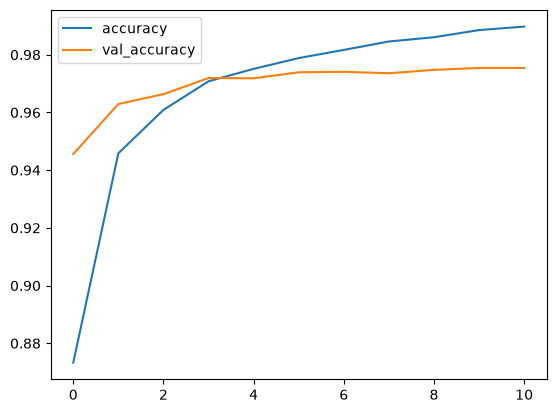

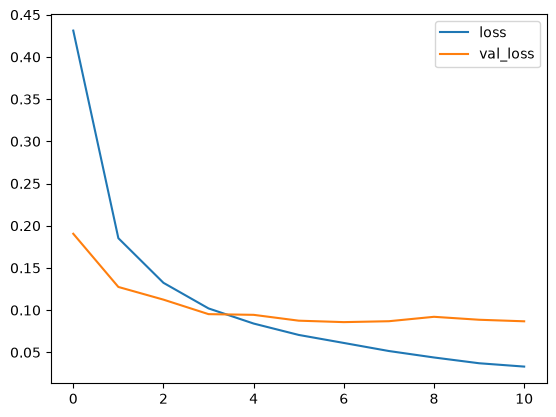

In [2]:
# a. Import necessary packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout


# b. Load training and testing data
train = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv")

x_train = train.drop(['label'], axis=1).values
y_train = train['label'].values

x_test = test.drop(['label'], axis=1).values
y_test = test['label'].values

# Normalize data
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# c. Define network architecture using Keras

model = Sequential()
model.add(Dense(128, input_shape=(784,), activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(10, activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# d. Train the model using SGD with 11 epochs

history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2
)


# e. Evaluate the network

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)


# f. Plot training loss and accuracy

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()